# PromoGuard: Promo Code Abuse Detection (CS 439 Stage 1)
Stage 1 notebook: early exploratory data analysis (EDA), derived fields, and a draft weighted risk score.

**Sections:** Libraries, EDA (size, frequency counts, constant columns), Derived Features (split into chunks), Descriptive Statistics (histograms, pair plot, z-scores), Flags and Risk Score, Outputs, Notes.

# Necessary Libraries and Dependencies

In [5]:
import pandas as pd
import numpy as np
from datetime import date
import re, os
import statsmodels
import sklearn
from sklearn.metrics import *
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn import metrics
from difflib import SequenceMatcher

import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)

# Exploratory Data Analysis
### Loading Data

In [6]:
PATH = "Promo_Abuse_Detection_Dataset.csv"
raw = pd.read_csv(PATH)
raw.head(10)

,Unnamed: 0,FirstName,LastName,Dob,Gender,UserId,Status,Email,Mobile,ProgramId,ProgramName,PostalCode,BadTryCount,LastLoginTime,PresentLoginTime,RegisteredOn,OS Type,Reg Referral Code,Reg Referral Prefix,Ref PC AC Number,Reg Client IP,Device Id,Sim Id,Meta Data
0,0,smt,shyani devi,28-05-1985,F,13260350,1,smtXXXXXX@gmail.com,8812569734,6019,PayZapp,509726,0,00:23:00,19:34:34,10/19/2020 18:45,Android,srpaa335,srpaa,IN017XXXXX1161,111.94.41.232,faid:y46GHDAWDVBGF1937ETsdfhd56483GDSSAA=:22b12,faid:y46GHDAWDVBGF1937ETsdfhd56483GDSSAA=:81b11,56641ab-7e57-4962-a362a89985
1,1,shakshi,sagar,09-06-1998,F,13454400,1,shaXXXXXX@gmail.com,8615389304,6019,PayZapp,772845,0,00:22:40,18:58:54,10/19/2020 18:45,Android,srpaa345,srpaa,IN017XXXXX1166,111.92.31.237,faid:y46GHDAWDVBGF1937ETsdfhd56483GDSSAA=:14b15,faid:y46GHDAWDVBGF1937ETsdfhd56483GDSSAA=:22b15,56641ab-7e57-4962-a362a89990
2,2,anshu,d/o,23-11-2001,F,13321313,1,ansXXXXXX@gmail.com,8418054019,6019,PayZapp,377130,0,00:22:32,18:44:38,10/19/2020 18:45,ios,srpaa349,srpaa,IN017XXXXX1168,111.94.91.346,iosvid:y46GHDAWDVBGF1937ETsdfhd56483GDSSAA=:81b16,faid:y46GHDAWDVBGF1937ETsdfhd56483GDSSAA=:14b16,56641ab-7e57-4962-a362a89992
3,3,kanika,kathuria,20-06-2001,F,12444655,1,kanXXXXXX@gmail.com,8055221226,6019,PayZapp,534482,0,00:22:30,18:41:04,10/19/2020 18:45,ios,srpaa350,srpaa,IN012XXXXX1162,111.94.41.237,iosvid:y46GHDAWDVBGF1937ETsdfhd56483GDSSAA=:81b17,iosvid:y46GHDAWDVBGF1937ETsdfhd56483GDSSAA=:81b16,56641ab-7e53-4962-a362a89967
4,4,riya,masi,18-07-2005,U,12547615,1,riyXXXXXX@gmail.com,8556603655,6019,PayZapp,258413,0,00:22:12,18:08:58,10/19/2020 18:45,Android,srpaa359,srpaa,IN017XXXXX1173,111.94.41.240,faid:y46GHDAWDVBGF1937ETsdfhd56483GDSSAA=:22b20,faid:y46GHDAWDVBGF1937ETsdfhd56483GDSSAA=:81b19,56641ab-7e57-4962-a362a89997
5,5,leela,with a child,13-04-1987,U,12379326,1,leeXXXXXX@gmail.com,9396979136,6019,PayZapp,261600,0,00:22:08,18:01:50,10/19/2020 18:45,Android,srpaa361,srpaa,IN017XXXXX1174,111.94.91.350,faid:y46GHDAWDVBGF1937ETsdfhd56483GDSSAA=:81b20,faid:y46GHDAWDVBGF1937ETsdfhd56483GDSSAA=:14b20,56641ab-7e57-4962-a362a89998
6,6,priya,jain,19-06-1992,M,13012510,1,priXXXXXX@gmail.com,7892860697,6019,PayZapp,514243,0,00:22:02,17:51:08,10/19/2020 18:45,Android,srpaa364,srpaa,IN012XXXXX1169,111.94.91.351,faid:y46GHDAWDVBGF1937ETsdfhd56483GDSSAA=:81b21,faid:y46GHDAWDVBGF1937ETsdfhd56483GDSSAA=:14b21,56641ab-7e53-4962-a362a89974
7,7,rakhi,@payal,04-05-1976,F,13269585,1,rakXXXXXX@gmail.com,9968252034,6019,PayZapp,563488,0,00:21:58,17:44:00,10/19/2020 18:45,Android,srpaa366,srpaa,IN012XXXXX1170,111.92.31.244,faid:y46GHDAWDVBGF1937ETsdfhd56483GDSSAA=:14b22,faid:y46GHDAWDVBGF1937ETsdfhd56483GDSSAA=:22b22,56641ab-7e53-4962-a362a89975
8,8,nitu,kumari,04-11-1991,F,12662481,1,nitXXXXXX@gmail.com,9343775398,6019,PayZapp,686171,0,00:21:52,17:33:18,10/19/2020 18:45,Android,srpaa369,srpaa,IN017XXXXX1178,111.92.31.245,faid:y46GHDAWDVBGF1937ETsdfhd56483GDSSAA=:14b23,faid:y46GHDAWDVBGF1937ETsdfhd56483GDSSAA=:22b23,56641ab-7e57-4962-a362a90002
9,9,tapas,das,15-09-2003,U,13186556,1,tapXXXXXX@gmail.com,8614879016,6019,PayZapp,626879,0,00:21:34,17:01:12,10/19/2020 18:45,Android,NaN,NaN,IN012XXXXX1176,111.92.31.248,faid:y46GHDAWDVBGF1937ETsdfhd56483GDSSAA=:14b26,faid:y46GHDAWDVBGF1937ETsdfhd56483GDSSAA=:22b26,56641ab-7e53-4962-a362a89981


### Raw Dataset Size

In [7]:
raw = pd.read_csv(PATH)

print("rows, cols (incl. index col):", raw.shape)
print("file bytes:", os.path.getsize(PATH), f"({os.path.getsize(PATH)/1024:.1f} KB)")
print("avg record size (bytes/row):", round(os.path.getsize(PATH) / len(raw), 1))
print("avg entry size (chars/cell):", round(raw.map(lambda x: len(str(x))).mean().mean(), 2))
print("pandas memory per row (bytes):", round(raw.memory_usage(deep=True).sum() / len(raw)))   # fixed: was len(df), df not defined yet
print("\ncolumn types:\n", raw.dtypes.value_counts())

rows, cols (incl. index col): (395, 24)
file bytes: 124364 (121.4 KB)
avg record size (bytes/row): 314.8
avg entry size (chars/cell): 12.11
pandas memory per row (bytes): 1137

column types:
 str      17
int64     7
Name: count, dtype: int64


### Cleaning: Drop Index Column, Missing Values, Data Types

In [8]:
df = raw.copy()
df = df.drop(columns=["Unnamed: 0"])  # drop the index column
# Maybe consider dropping some columns that are not useful for detection such as Status, ProgramID, ProgramName, BadTryCount
# since they are constant and show no change
print("shape after dropping index column:", df.shape)
missing = df.isna().sum()
print("\ncolumns with missing values:\n", missing[missing > 0])
print("\ndtypes:\n", df.dtypes)

shape after dropping index column: (395, 23)

columns with missing values:
 LastName               133
Gender                   2
Reg Referral Code       33
Reg Referral Prefix     33
dtype: int64

dtypes:
 FirstName                str
LastName                 str
Dob                      str
Gender                   str
UserId                 int64
Status                 int64
Email                    str
Mobile                 int64
ProgramId              int64
ProgramName              str
PostalCode             int64
BadTryCount            int64
LastLoginTime            str
PresentLoginTime         str
RegisteredOn             str
OS Type                  str
Reg Referral Code        str
Reg Referral Prefix      str
Ref PC AC Number         str
Reg Client IP            str
Device Id                str
Sim Id                   str
Meta Data                str
dtype: object


### Size of Dataset, Frequency Counts, and Constant Columns

In [9]:
print("rows, cols (index column dropped):", df.shape)
print("file bytes:", os.path.getsize(PATH), f"({os.path.getsize(PATH)/1024:.1f} KB)")
print("avg record size (bytes/row):", round(os.path.getsize(PATH) / len(df), 1))
print("avg entry size (chars/cell):", round(df.map(lambda x: len(str(x))).mean().mean(), 2))
print("pandas memory per row (bytes):", round(df.memory_usage(deep=True).sum() / len(df)))

rows, cols (index column dropped): (395, 23)
file bytes: 124364 (121.4 KB)
avg record size (bytes/row): 314.8
avg entry size (chars/cell): 12.52
pandas memory per row (bytes): 1129



Gender
 Gender
U      343
F       27
M       23
NaN      2
Name: count, dtype: int64

OS Type
 OS Type
Android    363
ios         32
Name: count, dtype: int64

Reg Referral Prefix
 Reg Referral Prefix
sarap    139
fagas     98
hdb       57
NaN       33
hdf       33
adgs      20
srpaa      9
wra        3
hdbr       3
Name: count, dtype: int64

RegisteredOn
 RegisteredOn
10/19/2020   19:00    352
10/19/2020   18:45     42
10/19/2020   18:46      1
Name: count, dtype: int64


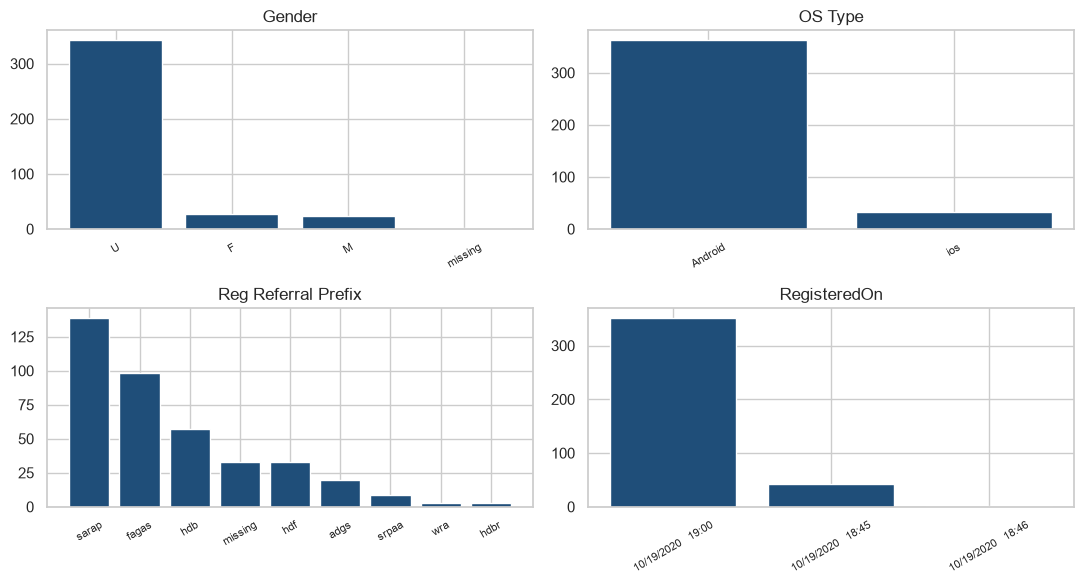

In [10]:
for c in ["Gender", "OS Type", "Reg Referral Prefix", "RegisteredOn"]:
    print(f"\n{c}\n", df[c].value_counts(dropna=False))

fig, ax = plt.subplots(2, 2, figsize=(11, 6))
for a, c in zip(ax.ravel(), ["Gender", "OS Type", "Reg Referral Prefix", "RegisteredOn"]):
    vc = df[c].fillna("missing").value_counts()
    a.bar(vc.index.astype(str), vc.values, color="#1F4E79")
    a.set_title(c); a.tick_params(axis="x", rotation=30, labelsize=8)
plt.tight_layout(); plt.show()

In [11]:
print("unique values per column:\n", df.nunique())
print("\nconstant columns:", [c for c in df.columns if df[c].nunique() == 1])

unique values per column:
 FirstName              309
LastName               183
Dob                    392
Gender                   3
UserId                 394
Status                   1
Email                  220
Mobile                 394
ProgramId                1
ProgramName              1
PostalCode             394
BadTryCount              1
LastLoginTime          392
PresentLoginTime       394
RegisteredOn             3
OS Type                  2
Reg Referral Code      362
Reg Referral Prefix      8
Ref PC AC Number       369
Reg Client IP          395
Device Id              389
Sim Id                 395
Meta Data              395
dtype: int64

constant columns: ['Status', 'ProgramId', 'ProgramName', 'BadTryCount']


In [12]:
print("email pattern sample:", df.Email.head(3).tolist())
print("share matching ^.{3}XXXXXX@:", df.Email.str.match(r"^.{3}XXXXXX@").mean())
print("unique emails:", df.Email.nunique(), "of", len(df), "rows")

email pattern sample: ['smtXXXXXX@gmail.com', 'shaXXXXXX@gmail.com', 'ansXXXXXX@gmail.com']
share matching ^.{3}XXXXXX@: 0.9949367088607595
unique emails: 220 of 395 rows


### Duplicate / Shared-Identifiers for Derived Features

In [13]:
def share_count(col):
    return df.groupby(col)[col].transform("count").where(df[col].notna(), 1)

for col, name in [("Mobile","MobileShare"), ("Email","EmailShare"), ("UserId","UserIdShare"),
                  ("Device Id","DeviceShare"), ("Sim Id","SimShare"), ("Reg Client IP","IPShare"),
                  ("Reg Referral Code","RefCodeShare"), ("Ref PC AC Number","RefAcctShare"),
                  ("PostalCode","PostalShare"), ("Dob","DobShare")]:
    df[name] = share_count(col)

share_cols = [c for c in df.columns if c.endswith("Share") and c != "NameShare"]
pd.DataFrame({"rows_in_dup_group": [(df[c] > 1).sum() for c in share_cols],
              "largest_group": [df[c].max() for c in share_cols]}, index=share_cols)

,rows_in_dup_group,largest_group
MobileShare,2,2.0
EmailShare,251,12.0
UserIdShare,2,2.0
DeviceShare,7,7.0
SimShare,0,1.0
IPShare,0,1.0
RefCodeShare,0,1.0
RefAcctShare,32,20.0
PostalShare,2,2.0
DobShare,6,2.0


#### IP features

In [14]:
octets = df["Reg Client IP"].str.split(".", expand=True).astype(int)
df["BadIP"]       = (octets > 255).any(axis=1)                       # impossible IP
df["Subnet24"]    = octets[0].astype(str)+"."+octets[1].astype(str)+"."+octets[2].astype(str)
df["Subnet16"]    = octets[0].astype(str)+"."+octets[1].astype(str)
df["Subnet24N"]   = df.groupby("Subnet24").Subnet24.transform("count")
df["Subnet16N"]   = df.groupby("Subnet16").Subnet16.transform("count")

print("invalid IP (any octet > 255):", df.BadIP.sum())
print("examples:", df.loc[df.BadIP, "Reg Client IP"].head(5).tolist())
print("\ntop /24 subnets:\n", df.Subnet24.value_counts().head(8))
print("\ntop /16 subnets:\n", df.Subnet16.value_counts().head(5))

invalid IP (any octet > 255): 88
examples: ['111.94.91.346', '111.94.91.350', '111.94.91.351', '111.94.91.358', '111.94.91.360']

top /24 subnets:
 Subnet24
42.34.11     38
48.24.11     38
14.21.11     38
95.29.11     37
22.32.11     37
111.94.41    30
111.92.31    27
111.94.91    26
Name: count, dtype: int64

top /16 subnets:
 Subnet16
111.94    56
42.34     38
48.24     38
14.21     38
95.29     37
Name: count, dtype: int64


#### Mobile, referral, device and SIM

In [15]:
df["MobilePrefix"]= df.Mobile.astype(str).str[:4]                     # first 4 digits
df["MobilePrefixN"]= df.groupby("MobilePrefix").MobilePrefix.transform("count")
df["RefAcctRegion"]= df["Ref PC AC Number"].str[:5]                   # e.g. IN312
df["RefAcctRegionN"]= df.groupby("RefAcctRegion").RefAcctRegion.transform("count")
df["RefPrefixN"]  = df.groupby("Reg Referral Prefix")["Reg Referral Prefix"].transform("count").where(df["Reg Referral Prefix"].notna(), 0)
df["NoReferral"]  = df["Reg Referral Code"].isna()

print("rows with no referral code:", df.NoReferral.sum())
print("\nmost common mobile prefixes:\n", df.MobilePrefix.value_counts().head(5))
print("\nreferral account regions:\n", df.RefAcctRegion.value_counts().head(5))

rows with no referral code: 33

most common mobile prefixes:
 MobilePrefix
9817    3
8772    3
9376    3
8812    2
7892    2
Name: count, dtype: int64

referral account regions:
 RefAcctRegion
IN312    82
IN522    57
IN672    57
IN612    56
IN393    55
Name: count, dtype: int64


In [16]:
dev = df["Device Id"].str.split(":", n=2, expand=True)
sim = df["Sim Id"].str.split(":", n=2, expand=True)
df["DevType"], df["DevToken"], df["DevSuffix"] = dev[0], dev[1], dev[2]
df["SimType"], df["SimToken"] = sim[0], sim[1]
df["DevTokenN"]   = df.groupby("DevToken").DevToken.transform("count")
df["DevSuffixN"]  = df.groupby("DevSuffix").DevSuffix.transform("count")
df["IsIOSdev"]    = df.DevType.str.startswith("ios")
df["OSMismatch"]  = (df["OS Type"].str.lower().eq("ios") != df.IsIOSdev)
df["DevSimMismatch"] = df.DevToken.ne(df.SimToken)

print("distinct device tokens:", df.DevToken.nunique(), "| distinct SIM tokens:", df.SimToken.nunique())
print("OS vs device-ID type mismatch:", df.OSMismatch.sum())
print("device token differs from SIM token:", df.DevSimMismatch.sum())
print("\nrows sharing a Device Id:")
df.loc[df.DeviceShare > 1, ["FirstName", "LastName", "Device Id", "DeviceShare"]]

distinct device tokens: 4 | distinct SIM tokens: 4
OS vs device-ID type mismatch: 1
device token differs from SIM token: 9

rows sharing a Device Id:


,FirstName,LastName,Device Id,DeviceShare
376,bharat,NaN,iosvd:++djsadjscior34728128MSASCDMVERww38rmbe8...,7
377,shubham,yadav,iosvd:++djsadjscior34728128MSASCDMVERww38rmbe8...,7
378,vivek,NaN,iosvd:++djsadjscior34728128MSASCDMVERww38rmbe8...,7
379,arman,ansari,iosvd:++djsadjscior34728128MSASCDMVERww38rmbe8...,7
380,raman,NaN,iosvd:++djsadjscior34728128MSASCDMVERww38rmbe8...,7
381,gaurav,NaN,iosvd:++djsadjscior34728128MSASCDMVERww38rmbe8...,7
382,sonia,NaN,iosvd:++djsadjscior34728128MSASCDMVERww38rmbe8...,7


#### Identity: age and names

In [17]:
ref = pd.Timestamp("2020-10-19")
dob = pd.to_datetime(df.Dob, format="%d-%m-%Y")
df["Age"]        = (ref - dob).dt.days / 365.25
df["Under18"]    = df.Age < 18
df["Jan1DOB"]    = (dob.dt.month == 1) & (dob.dt.day == 1)              # default-date pattern
df["FirstLen"]   = df.FirstName.str.len()
df["LastLen"]    = df.LastName.fillna("").str.len()
df["NoLastName"] = df.LastName.isna()
df["GenderUnk"]  = df.Gender.isna() | (df.Gender == "U")

print("under 18:", df.Under18.sum(), "| born Jan 1:", df.Jan1DOB.sum(), "| missing last name:", df.NoLastName.sum(), "| gender unknown:", df.GenderUnk.sum())
df.Age.describe().round(1)

under 18: 35 | born Jan 1: 0 | missing last name: 133 | gender unknown: 345


count    395.0
mean      30.6
std        9.2
min       14.8
25%       22.3
50%       30.3
75%       38.6
max       45.7
Name: Age, dtype: float64

In [18]:
fn = df.FirstName.str.lower().str.strip()
ln = df.LastName.fillna("").str.lower().str.strip()

def vowel_ratio(s):
    s = re.sub("[^a-z]", "", str(s).lower()); return sum(c in "aeiou" for c in s)/max(len(s),1)
def max_consonant_run(s):
    runs = re.findall(r"[^aeiou\W\d_]+", str(s).lower()); return max((len(r) for r in runs), default=0)

honorifics = {"smt","smt.","md","md.","mohd","sri","shri","mr","mrs","ms"}
df["VowelRatio"] = fn.map(vowel_ratio)
df["ConsRun"]    = fn.map(max_consonant_run)
df["Gibberish"]  = (((df.VowelRatio < .15) & (df.FirstLen >= 3) & ~fn.isin(honorifics)) | (df.FirstLen <= 1))
df["Honorific"]  = fn.isin(honorifics) | fn.str.startswith("smt.")
df["SpecialChar"]= df.FirstName.str.contains(r"[^a-zA-Z ]") | df.LastName.fillna("").str.contains(r"[^a-zA-Z ]")
df["HasAlias"]   = ln.str.contains("@")
df["RepeatedChar"]= fn.map(lambda s: bool(re.search(r"(.)\1\1", s)))
df["SameFirstLast"]= (fn == ln) & (ln != "")
df["NameShare"]  = df.groupby([fn, ln]).FirstName.transform("count")
df["EmailNameMatch"] = df.Email.str[:3].str.lower() == fn.str[:3]
df["EmailNameMismatch"] = ~df["EmailNameMatch"]

print("gibberish first names:", df.Gibberish.sum(), df.FirstName[df.Gibberish].tolist())
print("honorific-only names:", df.Honorific.sum(), "| special chars:", df.SpecialChar.sum(), "| '@ alias':", df.HasAlias.sum())
print("repeated characters:", df.RepeatedChar.sum(), "| first == last:", df.SameFirstLast.sum())
print("email prefix does not match first name:", df.EmailNameMismatch.sum())
df.loc[df.Gibberish | df.RepeatedChar, ["FirstName", "LastName", "VowelRatio", "ConsRun"]]

gibberish first names: 8 ['asdcdfs', 'b', 'jtyrhre', 'dfcsfcs', 'sdsfds', 'dscdfvd', 'fcsss', 'dfvdv']
honorific-only names: 17 | special chars: 50 | '@ alias': 33
repeated characters: 1 | first == last: 0
email prefix does not match first name: 2


,FirstName,LastName,VowelRatio,ConsRun
259,asdcdfs,NaN,0.142857,6
317,b,vikjay kumar,0.000000,1
326,jtyrhre,NaN,0.142857,6
359,dfcsfcs,NaN,0.000000,7
374,sdsfds,NaN,0.000000,6
390,dscdfvd,NaN,0.000000,7
392,fcsss,NaN,0.000000,5
394,dfvdv,NaN,0.000000,5


#### Near-duplicate names (fuzzy matching)

In [19]:
# near-duplicate names (fuzzy), O(n^2) is fine for ~400 rows
full = (fn + " " + ln).str.strip().tolist()
near = np.zeros(len(df), dtype=int)
pairs = []
for i in range(len(full)):
    for j in range(i+1, len(full)):
        if full[i] != full[j] and len(full[i]) > 4 and SequenceMatcher(None, full[i], full[j]).ratio() >= .85:
            near[i] += 1; near[j] += 1
            pairs.append((i, j, full[i], full[j]))
df["NearDupName"] = near

print("records with a near-duplicate name:", (df.NearDupName > 0).sum(), "| pairs:", len(pairs))
pd.DataFrame(pairs, columns=["row_i", "row_j", "name_i", "name_j"]).head(15)

records with a near-duplicate name: 23 | pairs: 12


,row_i,row_j,name_i,name_j
0,37,251,raj kumari,anju kumari
1,43,291,vikash,vikas
2,88,112,suraj singh,raju singh
3,108,278,sunil kumar,anil kumar
4,126,330,abhishekh,abhishek
5,160,176,rekhai,rekha
6,161,389,gajender kumar,mahender kumar
7,175,230,smt. sarswati devi,smt saraswati devi
8,194,268,shiv kumari,shiv kumar
9,199,203,asma khatun,seema khatun


#### Login-time and registration-time

In [20]:
def to_sec(s):
    m_ = re.fullmatch(r"(\d{1,2}):(\d{2}):(\d{2})", str(s))
    return np.nan if m_ is None else int(m_[1])*3600 + int(m_[2])*60 + int(m_[3])
df["LastLoginSec"]    = df.LastLoginTime.map(to_sec)
df["PresentLoginSec"] = df.PresentLoginTime.map(to_sec)
df["BadLoginTime"]    = df.LastLoginSec.isna() | df.PresentLoginSec.isna()   # malformed value, e.g. "01-01-1900 00:00"
df["LoginGapSec"]     = df.PresentLoginSec - df.LastLoginSec
df["SameLoginTime"]   = df.groupby("PresentLoginTime").PresentLoginTime.transform("count") > 1
df["RegTS"]           = pd.to_datetime(df.RegisteredOn, format="%m/%d/%Y %H:%M")
df["RegTSN"]          = df.groupby("RegTS").RegTS.transform("count")      # velocity: sign-ups in same minute
print("distinct registration minutes:", df.RegTS.nunique())
print("sign-ups per registration minute:\n", df.RegTS.value_counts())
print("\nmalformed login times:", df.BadLoginTime.sum())
print(df.loc[df.BadLoginTime, ["FirstName", "LastLoginTime", "PresentLoginTime"]].to_string())
df.LoginGapSec.describe().round(0)

distinct registration minutes: 3
sign-ups per registration minute:
 RegTS
2020-10-19 19:00:00    352
2020-10-19 18:45:00     42
2020-10-19 18:46:00      1
Name: count, dtype: int64

malformed login times: 1
    FirstName     LastLoginTime PresentLoginTime
340    esrail  01-01-1900 00:00         02:33:34


count      394.0
mean     -1129.0
std      39295.0
min     -86090.0
25%     -26137.0
50%        618.0
75%      24319.0
max      85110.0
Name: LoginGapSec, dtype: float64

### Descriptive Statistics and Distributions (mean, standard deviation, histograms)

         Age  PostalCode  FirstLen  LastLen  EmailShare
count  395.0       395.0     395.0    395.0       395.0
mean    30.6    535340.6       5.7      4.4         3.3
std      9.2    179286.1       1.6      4.4         3.1
min     14.8    236378.0       1.0      0.0         1.0
max     45.7    876333.0      13.0     28.0        12.0


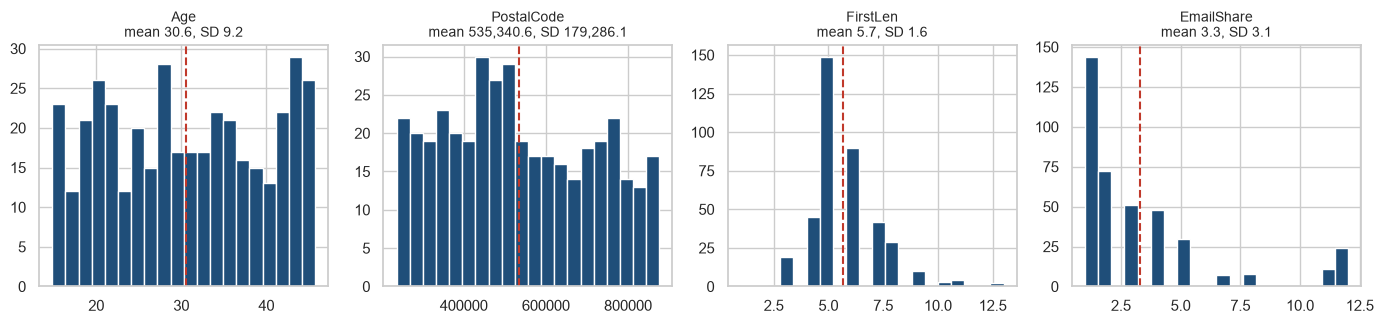

In [21]:
num = ["Age", "PostalCode", "FirstLen", "LastLen", "EmailShare"]    # EmailShare = number of rows sharing the same masked email
display_tbl = df[num].agg(["count", "mean", "std", "min", "max"]).round(1)
print(display_tbl)

fig, ax = plt.subplots(1, 4, figsize=(14, 3.4))
for a, c in zip(ax, ["Age", "PostalCode", "FirstLen", "EmailShare"]):
    a.hist(df[c], bins=20, color="#1F4E79", edgecolor="white")
    a.axvline(df[c].mean(), color="#C0392B", ls="--")
    a.set_title(f"{c}\nmean {df[c].mean():,.1f}, SD {df[c].std():,.1f}", fontsize=10)
plt.tight_layout(); plt.show()

### Pair Plot

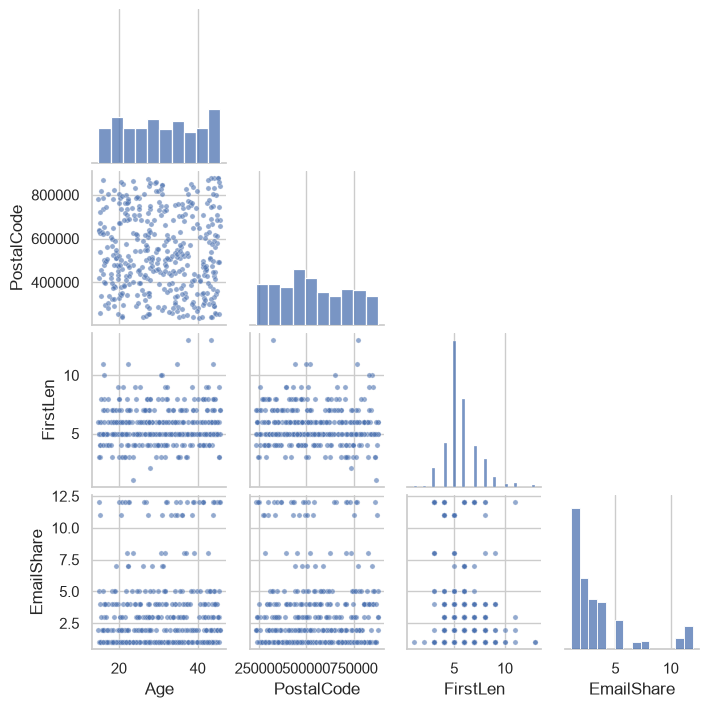

,Age,PostalCode,FirstLen,LastLen,EmailShare
Age,1.00,-0.04,0.05,-0.02,0.11
PostalCode,-0.04,1.00,-0.05,-0.06,-0.01
FirstLen,0.05,-0.05,1.00,-0.16,-0.11
LastLen,-0.02,-0.06,-0.16,1.00,0.04
EmailShare,0.11,-0.01,-0.11,0.04,1.00


In [22]:
sns.pairplot(df[["Age", "PostalCode", "FirstLen", "EmailShare"]], corner=True, height=1.8, plot_kws=dict(s=14, alpha=.6))
plt.show()
df[["Age", "PostalCode", "FirstLen", "LastLen", "EmailShare"]].corr().round(2)   # correlation coefficients, to back up the pair plot

### z-Score Distributions

|z| > 3: {'Age': 0, 'PostalCode': 0, 'FirstLen': 6, 'LastLen': 5, 'EmailShare': 0}
|z| > 2: {'Age': 0, 'PostalCode': 0, 'FirstLen': 21, 'LastLen': 13, 'EmailShare': 35}


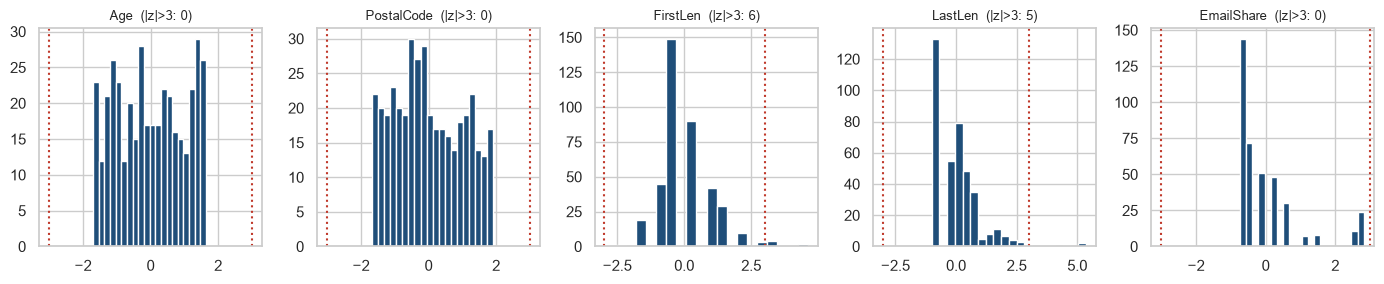


longest first/last names (the z-score outliers):


,FirstName,LastName,FirstLen,LastLen
18,laxmi,devi w/o late sh hukan chand,5,28
23,smt.farhana,baigum,11,6
70,naval kishore,kishore,13,7
111,brahamprakash,s/o meer singh,13,14
186,pooja,prajapati @ pratibha,5,20
218,madhu,shukla @ shabana ben ajmeri,5,27
223,sona,devi with a child krishna,4,25
284,raghunandan,das,11,3
318,dolly,@ rekha w/o monto shah,5,22
347,nikhleshwar,bhagat,11,6


In [23]:
# z = (value - mean) / SD  -> how many standard deviations a value is from the column average; |z| > 3 is a common outlier cutoff
zc = ["Age", "PostalCode", "FirstLen", "LastLen", "EmailShare"]
Z = (df[zc] - df[zc].mean()) / df[zc].std()
print("|z| > 3:", (Z.abs() > 3).sum().to_dict())
print("|z| > 2:", (Z.abs() > 2).sum().to_dict())

fig, ax = plt.subplots(1, 5, figsize=(14, 3))
for a, c in zip(ax, zc):
    a.hist(Z[c], bins=20, color="#1F4E79", edgecolor="white")
    a.axvline(-3, color="#C0392B", ls=":"); a.axvline(3, color="#C0392B", ls=":")
    a.set_title(f"{c}  (|z|>3: {(Z[c].abs() > 3).sum()})", fontsize=9)
plt.tight_layout(); plt.show()

print("\nlongest first/last names (the z-score outliers):")
df.loc[(Z.FirstLen.abs() > 3) | (Z.LastLen.abs() > 3), ["FirstName", "LastName", "FirstLen", "LastLen"]]

### Spotlight: Likely Duplicate Accounts

In [25]:
# rows sharing a mobile, UserId, or full name are the strongest evidence in this file
dups = df[(df.MobileShare > 1) | (df.UserIdShare > 1) | (df.NameShare > 1)]
print("records involved:", len(dups))
dups[["FirstName", "LastName", "Dob", "Mobile", "UserId", "Email", "Reg Client IP", "Device Id"]].T

records involved: 35


,16,17,46,71,74,75,76,85,108,129,136,137,139,141,143,164,261,263,270,273,285,290,292,302,306,312,323,325,328,329,350,356,375,378,385
FirstName,aanamika,aanamika,sanjay,sanjay,raman,raman,rohit,dinesh,sunil,vinod,dinesh,rakesh,kuldeep,vivek,sanjay,amit,rahul,akash,rohit,rohit,sanjay,rahul,vinod,jagdish,kuldeep,rohit,guddu,amit,rakesh,guddu,sunil,akash,jagdish,vivek,rohit
LastName,misra,misra,NaN,NaN,ralhan,ralhan,NaN,NaN,kumar,NaN,NaN,NaN,NaN,NaN,NaN,kumar,NaN,gupta,NaN,NaN,NaN,NaN,NaN,NaN,NaN,kumar,NaN,kumar,NaN,NaN,kumar,gupta,NaN,NaN,kumar
Dob,29-07-1976,30-07-1976,21-12-1975,27-08-1976,12-03-1984,10-08-1998,21-07-1977,29-01-1996,14-04-1993,03-12-1984,17-11-1993,01-09-2003,06-08-2004,28-08-1976,05-09-1981,16-03-1980,13-09-2005,12-11-1978,30-03-1994,05-09-2001,20-09-1988,04-06-1995,26-07-1980,22-09-1984,06-03-1987,06-01-1992,05-02-2000,14-10-1996,14-12-1975,01-09-1978,18-03-1996,26-11-1985,17-04-1981,23-09-2004,19-03-1996
Mobile,9769827490,9769827490,8967254698,8322574629,8114450098,8764088524,7870957923,9076781174,8157562831,9226470178,9213707961,9047142410,9159810706,8166507859,7896154942,9182648667,7849523318,7794592890,9118530715,8641043854,8795811020,9968491469,8339472675,9299539582,8804882958,9286528424,9678147178,9911684436,9372824599,8772244273,8431968894,8452191768,8179138357,8673965499,9662052367
UserId,13341428,13341428,13232396,13005431,12823020,12928391,13311110,13187800,13029928,12735248,12475322,13343729,12368779,12568838,12389854,12620052,13332669,12376281,12645319,12725972,12533752,13357068,13308867,12501964,12744406,12597514,12567182,13009239,12598321,13410368,13246264,12467246,12668535,13349154,12687936
Email,aanXXXXXX@gmail.com,aanXXXXXX@gmail.com,sanXXXXXX@gmail.com,sanXXXXXX@gmail.com,ramXXXXXX@gmail.com,ramXXXXXX@gmail.com,rohXXXXXX@gmail.com,dinXXXXXX@gmail.com,sunXXXXXX@gmail.com,vinXXXXXX@gmail.com,dinXXXXXX@gmail.com,rakXXXXXX@gmail.com,kulXXXXXX@gmail.com,vivXXXXXX@gmail.com,sanXXXXXX@gmail.com,amiXXXXXX@gmail.com,rahXXXXXX@gmail.com,akaXXXXXX@gmail.com,rohXXXXXX@gmail.com,rohXXXXXX@gmail.com,sanXXXXXX@gmail.com,rahXXXXXX@gmail.com,vinXXXXXX@gmail.com,jagXXXXXX@gmail.com,kulXXXXXX@gmail.com,rohXXXXXX@gmail.com,gudXXXXXX@gmail.com,amiXXXXXX@gmail.com,rakXXXXXX@gmail.com,gudXXXXXX@gmail.com,sunXXXXXX@gmail.com,akaXXXXXX@gmail.com,jagXXXXXX@gmail.com,vivXXXXXX@gmail.com,rohXXXXXX@gmail.com
Reg Client IP,111.94.91.360,111.94.91.361,22.32.11.40,22.32.11.45,48.24.11.108,14.21.11.70,22.32.11.46,14.21.11.72,42.34.11.56,48.24.11.119,22.32.11.58,95.29.11.83,48.24.11.121,22.32.11.59,42.34.11.63,48.24.11.126,1.49.90.39,1.49.90.40,1.49.90.42,1.49.90.21,203.88.145.221,304.06.169.332,203.52.175.222,304.06.169.335,304.06.169.336,203.52.175.227,206.94.198.230,203.88.145.231,203.52.175.231,203.88.145.232,304.06.169.347,42.34.11.29,95.29.11.54,14.21.11.56,95.29.11.62
Device Id,faid:y46GHDAWDVBGF1937ETsdfhd56483GDSSAA=:81b30,faid:y46GHDAWDVBGF1937ETsdfhd56483GDSSAA=:81b31,tusd:++djsadjscior34728128FSASCDFVERww38rfbe8=...,tusd:++djsadjscior34728128FSASCDFVERww38rfbe8=...,tusd:++djsadjscior34728128FSASCDFVERww38rfbe8=...,tusd:++djsadjscior34728128FSASCDFVERww38rfbe8=...,tusd:++djsadjscior34728128FSASCDFVERww38rfbe8=...,tusd:++djsadjscior34728128FSASCDFVERww38rfbe8=...,tusd:++djsadjscior34728128FSASCDFVERww38rfbe8=...,tusd:++djsadjscior34728128FSASCDFVERww38rfbe8=...,tusd:++djsadjscior34728128FSASCDFVERww38rfbe8=...,tusd:++djsadjscior34728128FSASCDFVERww38rfbe8=...,tusd:++djsadjscior34728128FSASCDFVERww38rfbe8=...,tusd:++djsadjscior34728128FSASCDFVERww38rfbe8=...,tusd:++djsadjscior34728128FSASCDFVERww38rfbe8=...,tusd:++djsadjscior34728128FSASCDFVERww38rfbe8=...,iosid:++djsajacior34728128FSASCDFVERww38rfbe8=...,iosid:++djsajacior34728128FSASCDFVERww38rfbe8=...,tiadid:++djsajacior34728128FSASCDFVERww38rfbe8...,tiadid:++djsajacior34728128FSASCDFVERww38rfbe8...,tiadid:++djsajacior34728128FSASCDFVERww38rfbe8...,tiadid:++djsajacior34728128FSASCDFVERww38rfbe8...,tiadid:++djsajacior34728128FSASCDFVERww38rfbe8...,tiadid:++djsajac

### Flags and weighted risk score

In [26]:
W = {   # weight = how suspicious I judge the signal; TUNE THESE and justify in your report
    "Gibberish":          3.0,
    "DeviceShare>1":      2.5,
    "BadIP":              2.0,
    "NearDupName>0":      1.5,
    "EmailShare>1":       1.5,   # weak: email is masked
    "Subnet24N>=30":      1.5,   # dense /24 (stricter than >=20)
    "RefAcctShare>1":     1.5,
    "NoReferral":         1.0,
    "NoLastName":         1.0,
    "Honorific":          1.0,
    "Under18":            1.0,
    "OSMismatch":         1.0,
    "EmailNameMismatch":  1.0,
    "MobileShare>1":      2.0,
    "UserIdShare>1":      2.0,
    "SpecialChar":        0.5,
    "GenderUnk":          0.5,
    "RepeatedChar":       0.5,
    "BadLoginTime":       1.0,
}
pd.Series(W, name="weight").sort_values(ascending=False).to_frame()

,weight
Gibberish,3.0
DeviceShare>1,2.5
BadIP,2.0
UserIdShare>1,2.0
MobileShare>1,2.0
NearDupName>0,1.5
EmailShare>1,1.5
Subnet24N>=30,1.5
RefAcctShare>1,1.5
OSMismatch,1.0


In [27]:
F = pd.DataFrame({
    "Gibberish": df.Gibberish, "DeviceShare>1": df.DeviceShare > 1, "BadIP": df.BadIP,
    "NearDupName>0": df.NearDupName > 0, "EmailShare>1": df.EmailShare > 1,
    "Subnet24N>=30": df.Subnet24N >= 30, "RefAcctShare>1": df.RefAcctShare > 1,
    "NoReferral": df.NoReferral, "NoLastName": df.NoLastName, "Honorific": df.Honorific,
    "Under18": df.Under18, "OSMismatch": df.OSMismatch, "EmailNameMismatch": df.EmailNameMismatch,
    "MobileShare>1": df.MobileShare > 1, "UserIdShare>1": df.UserIdShare > 1,
    "SpecialChar": df.SpecialChar, "GenderUnk": df.GenderUnk, "RepeatedChar": df.RepeatedChar, "BadLoginTime": df.BadLoginTime,
})
w = pd.Series(W)
df["RiskScore"] = (F.mul(w, axis=1).sum(axis=1) / w.sum() * 100).round(1)
df["NumFlags"]  = F.sum(axis=1)
# max possible score is ~100 only if every flag fires, so fixed cutoffs make little sense; use percentiles
q70, q90 = df.RiskScore.quantile([.70, .90])
df["Tier"]      = pd.cut(df.RiskScore, [-1, q70, q90, 101], labels=["Green", "Yellow", "Red"])

# "why was it flagged": list of flags raised per record
df["Reasons"] = F.apply(lambda r: ", ".join(r.index[r.values]), axis=1)
print(f"tier cutoffs: Green <= {q70:.1f} < Yellow <= {q90:.1f} < Red")
df[["RiskScore", "NumFlags", "Tier"]].describe(include="all")

tier cutoffs: Green <= 17.3 < Yellow <= 21.2 < Red


,RiskScore,NumFlags,Tier
count,395.000000,395.000000,395
unique,NaN,NaN,3
top,NaN,NaN,Green
freq,NaN,NaN,317
mean,13.941772,3.162025,NaN
std,5.582219,1.053915,NaN
min,0.000000,0.000000,NaN
25%,9.600000,2.000000,NaN
50%,13.500000,3.000000,NaN
75%,17.300000,4.000000,NaN


### Graph of Linked Records

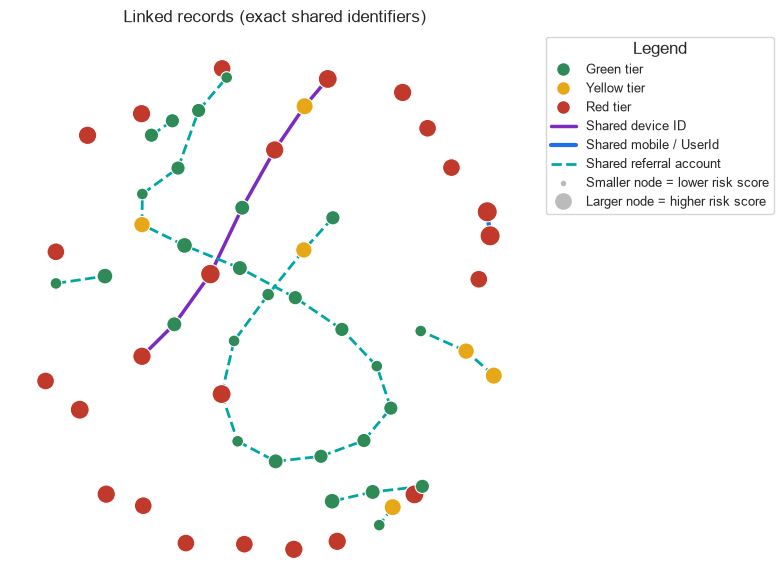

58 nodes, 33 edges, 25 components


In [31]:
import networkx as nx
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

TC = {"Green": "#2E8B57", "Yellow": "#E6A817", "Red": "#C0392B"}      # node colors (risk tier)
# edge style per shared identifier: (color, line style, width) - colors avoid the node colors
EDGE = {"Device Id":        ("#7B2CBF", "solid",  2.5),   # purple
        "Mobile":           ("#1F6FEB", "solid",  3.0),   # blue
        "UserId":           ("#1F6FEB", "solid",  3.0),   # blue (same as Mobile)
        "Ref PC AC Number": ("#00A6A6", "dashed", 2.0)}    # teal, dashed

sub = df[(df.Tier == "Red") | (df.DeviceShare > 1) | (df.MobileShare > 1)
         | (df.UserIdShare > 1) | (df.RefAcctShare > 1)]

G = nx.Graph()
G.add_nodes_from(sub.index)
for key in EDGE:
    for _, idx in sub.groupby(key).groups.items():
        idx = list(idx)
        for i in range(len(idx) - 1):          # chain edges between records sharing the value
            G.add_edge(idx[i], idx[i + 1], kind=key)

pos = nx.spring_layout(G, seed=4, k=.3)
fig, ax = plt.subplots(figsize=(8, 6))
for key, (color, style, width) in EDGE.items():          # draw each edge type separately
    es = [(u, v) for u, v, d in G.edges(data=True) if d["kind"] == key]
    nx.draw_networkx_edges(G, pos, edgelist=es, ax=ax, edge_color=color, style=style, width=width)
nx.draw_networkx_nodes(G, pos, ax=ax, node_size=[25 + df.RiskScore[n] * 6 for n in G],
                       node_color=[TC[df.Tier[n]] for n in G], edgecolors="white", linewidths=0.8)

legend_items = (
    [Line2D([0], [0], marker="o", color="w", markerfacecolor=c, markersize=10, label=f"{t} tier") for t, c in TC.items()]
    + [Line2D([0], [0], color="#7B2CBF", lw=2.5, label="Shared device ID"),
       Line2D([0], [0], color="#1F6FEB", lw=3, label="Shared mobile / UserId"),
       Line2D([0], [0], color="#00A6A6", lw=2, ls="--", label="Shared referral account"),
       Line2D([0], [0], marker="o", color="w", markerfacecolor="#BBBBBB", markersize=5, label="Smaller node = lower risk score"),
       Line2D([0], [0], marker="o", color="w", markerfacecolor="#BBBBBB", markersize=13, label="Larger node = higher risk score")]
)
ax.legend(handles=legend_items, loc="upper left", bbox_to_anchor=(1.0, 1.0), frameon=True, fontsize=9, title="Legend")
ax.set_title("Linked records (exact shared identifiers)"); ax.axis("off")
plt.tight_layout(); plt.show()
print(len(G), "nodes,", G.number_of_edges(), "edges,", nx.number_connected_components(G), "components")

### Outputs

In [ ]:
print("Flag counts:\n", F.sum().sort_values(ascending=False))
print("\nRisk score summary:\n", df.RiskScore.describe().round(1))
print("\nTier counts:\n", df.Tier.value_counts())

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
F.sum().sort_values().plot.barh(ax=ax[0], color="#1F4E79"); ax[0].set_title("Flags raised (count)")
cols = {"Green": "#2E8B57", "Yellow": "#E6A817", "Red": "#C0392B"}
for t in ["Green", "Yellow", "Red"]:
    ax[1].hist(df.loc[df.Tier == t, "RiskScore"], bins=np.arange(0, 36, 1.5), color=cols[t], label=t)
ax[1].set_title("Risk score by tier"); ax[1].set_xlabel("RiskScore"); ax[1].legend()
plt.tight_layout(); plt.show()

In [ ]:
top = df.sort_values("RiskScore", ascending=False)[["FirstName","LastName","RiskScore","Tier","Reasons"]].head(10)
print(top.to_string())
df.to_csv("promoguard_scored.csv", index=False)       # load this into SQLite / the dashboard
print("\nsaved promoguard_scored.csv:", df.shape)

### Notes and Limitations
- The dataset has **no abuse labels**, so the risk score ranks suspicious-looking registrations; it cannot measure detection accuracy.
- **Emails are masked** (first 3 letters + XXXXXX), so `EmailShare` is a weak signal.
- Weights are **judgment calls**; justify or tune them in the report. Several flags (gender unknown, shared masked email, dense subnet) fire on most rows and add little separation.
- Stage 1 findings are anomalies to investigate, not confirmed abusers.